# Lab 02 · NumPy for Numerical Computing
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 5** (C-3 Apply, PLO 5 Modern Tool Usage): *Use Python programming and tools to perform data handling and basic operations.*

**Name:** Shahzad Ahmed Awan **Roll No:** 2024-SE-15

### Datasets (run this cell first, do not edit)
- **Census 2023**: Pakistan Bureau of Statistics, 7th Population and Housing Census (provinces, ICT, AJK, GB).
- **Climate**: 1991–2020 climate normals (PMD / WMO) as published in the city climate tables.
- **Inflation**: Pakistan Economic Survey 2024-25, Chapter 7, Fig 7.1 (PBS CPI, year-on-year %).
- **Marks**: sample lab-section marks.

In [1]:
import numpy as np

# ===================== DATASETS (given to students in the starter notebook) =====================
# D1. Population Census 2023 (PBS), source: 2023 Pakistani census results
units = np.array(["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Islamabad", "AJK", "Gilgit-Baltistan"])
pop_2023 = np.array([127_688_922, 55_696_147, 40_856_097, 14_894_402, 2_363_863, 4_333_467, 1_709_049])
pop_2017 = np.array([109_989_655, 47_854_510, 35_501_964, 12_335_129, 2_003_368, 4_045_367, 1_492_924])

# D2. Climate normals 1991-2020 (PMD / WMO), mean daily maximum temperature (°C) and rainfall (mm)
cities = np.array(["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"])
months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
tmax = np.array([
    [18.4, 22.2, 27.5, 34.2, 38.9, 38.9, 35.6, 34.7, 34.4, 32.4, 27.1, 21.4],   # Lahore
    [26.3, 28.7, 32.6, 35.0, 35.7, 35.7, 33.6, 32.5, 33.4, 35.6, 32.6, 28.4],   # Karachi
    [17.7, 20.0, 24.8, 30.6, 36.1, 38.3, 35.4, 33.9, 33.4, 30.9, 25.4, 20.4],   # Islamabad
    [18.1, 20.1, 24.7, 30.6, 36.5, 39.6, 37.4, 35.9, 34.8, 31.0, 25.2, 20.6],   # Peshawar
    [11.8, 14.0, 19.5, 25.9, 31.4, 35.5, 36.8, 35.4, 31.9, 26.0, 19.6, 14.6]])  # Quetta
rain = np.array([
    [21.9, 31.5, 31.5, 19.5, 17.7, 73.8, 188.6, 177.1, 88.6, 10.3, 6.9, 6.8],
    [10.6, 5.5, 3.2, 11.1, 9.2, 24.6, 86.1, 104.7, 44.0, 12.7, 0.7, 5.6],
    [55.2, 93.4, 95.2, 58.1, 39.9, 78.4, 310.6, 317.0, 135.4, 34.4, 17.7, 25.9],
    [39.8, 69.9, 78.2, 68.1, 26.7, 25.4, 69.0, 68.5, 34.8, 26.7, 16.9, 17.3],
    [55.0, 58.4, 49.5, 40.0, 17.8, 3.2, 8.8, 4.9, 4.2, 4.5, 19.3, 34.6]])

# D3. CPI inflation, year-on-year % (Pakistan Economic Survey 2024-25, Fig 7.1, from PBS)
cpi_months = np.array(["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
cpi = np.array([[28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3, 23.1, 20.7, 17.3],    # FY2024
                [11.1,  9.6,  6.9,  7.2,  4.9,  4.1,  2.4,  1.5,  0.7,  0.3]])   # FY2025

# D4. Marks of one lab section (sample class data)
marks = np.array([45, 78, 92, 38, 66, 97, 49, 55, 71, 83])

### Helper for tidy output
Used only to print the results as neat tables in the later tasks. It is not part of any task.

In [2]:
# helper: prints names and values as an aligned table (np.char only, no loops)
def table(names, values, fmt="%.2f", unit="", width=20):
    names = np.asarray(names).astype(str)
    values = np.asarray(values)
    text = values.astype(str) if fmt is None else np.char.mod(fmt, values)
    rows = np.char.add(np.char.ljust(names, width), np.char.add(np.char.rjust(text, 10), unit))
    return "\n".join(np.char.add("     ", rows))

## Task 1 · Setup
Import NumPy as `np` and print its version.

In [3]:
# T1
import numpy as np

print("T1: NumPy version =", np.__version__)

T1: NumPy version = 2.5.4


## Task 2 · Class register: creating arrays
Your lab section has 10 students.
- **(a)** An attendance array of 10 zeros.
- **(b)** A "fee paid" array of 10 ones.
- **(c)** An array giving every student 5 grace marks (10 fives).
- **(d)** Roll numbers 10 to 50 (inclusive).
- **(e)** Only the even roll numbers from 10 to 50.
- **(f)** A 3 × 3 seat map holding the values 0 to 8.
- **(g)** A 3 × 3 identity matrix.

In [4]:
# T2
attendance = np.zeros(10)                  # (a)
fee_paid = np.ones(10)                     # (b)
grace = np.full(10, 5)                     # (c)
roll_numbers = np.arange(10, 51)           # (d) stop value is excluded, so 51
even_rolls = np.arange(10, 51, 2)          # (e)
seat_map = np.arange(9).reshape(3, 3)      # (f)
identity = np.eye(3)                       # (g)

print("T2a: attendance (10 zeros)")
print("    ", attendance, "\n")
print("T2b: fee paid (10 ones)")
print("    ", fee_paid, "\n")
print("T2c: grace marks (10 fives)")
print("    ", grace, "\n")
print("T2d: roll numbers 10 to 50")
print("    ", roll_numbers, "\n")
print("T2e: even roll numbers 10 to 50")
print("    ", even_rolls, "\n")
print("T2f: 3 x 3 seat map (0 to 8)")
print(seat_map, "\n")
print("T2g: 3 x 3 identity matrix")
print(identity)

T2a: attendance (10 zeros)
     [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.] 

T2b: fee paid (10 ones)
     [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.] 

T2c: grace marks (10 fives)
     [5 5 5 5 5 5 5 5 5 5] 

T2d: roll numbers 10 to 50
     [10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50] 

T2e: even roll numbers 10 to 50
     [10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50] 

T2f: 3 x 3 seat map (0 to 8)
[[0 1 2]
 [3 4 5]
 [6 7 8]] 

T2g: 3 x 3 identity matrix
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## Task 3 · Randomness and reproducibility
- **(a)** Set `np.random.seed(2026)`, then generate one random number between 0 and 1.
- **(b)** Generate 25 numbers from the standard normal distribution.
- **(c)** Set `np.random.seed(42)` and roll 10,000 Ludo dice with `np.random.randint`. Count each face with `np.unique(..., return_counts=True)`.
- **(d)** Estimate P(six) and compare it with 1/6.
- **(e)** Count how many times two sixes came in a row (no loops).

In [5]:
# T3
np.random.seed(2026)
one_rand = np.random.rand()                # (a)
normals = np.random.randn(25)              # (b)
print("T3a: one random number between 0 and 1 (seed 2026)")
print("    ", one_rand, "\n")
print("T3b: 25 standard normal numbers")
print(normals, "\n")

np.random.seed(42)
dice = np.random.randint(1, 7, size=10000)           # (c) 10,000 Ludo dice
faces, counts = np.unique(dice, return_counts=True)
print("T3c: how often each face came up in 10,000 rolls (seed 42)")
print(table(faces, counts, fmt="%d", unit=" times", width=6), "\n")

p_six = (dice == 6).mean()                           # (d)
print("T3d: estimated P(six) compared with 1/6")
print(f"     P(six) = {p_six:.4f}   1/6 = {1/6:.4f}   difference = {p_six - 1/6:+.4f}\n")

is_six = dice == 6                                   # (e) two sixes in a row
double_sixes = np.sum(is_six[:-1] & is_six[1:])
print("T3e: two sixes in a row")
print("    ", double_sixes, "times")

T3a: one random number between 0 and 1 (seed 2026)
     0.21934563492692294 

T3b: 25 standard normal numbers
[ 0.34904966 -0.06370324 -0.04437885 -0.88093025  0.12030048  0.85029072
 -0.69607647  0.99810635 -1.58120639 -0.79589368  2.00615572 -1.78051281
  1.41324558 -0.99029074 -0.31637995 -0.44678319 -1.25614422  0.67975016
 -0.04040287 -0.61953965  0.74720313  0.3595902   0.22039541  1.98726071
 -1.6745924 ] 

T3c: how often each face came up in 10,000 rolls (seed 42)
     1           1665 times
     2           1692 times
     3           1625 times
     4           1672 times
     5           1689 times
     6           1657 times 

T3d: estimated P(six) compared with 1/6
     P(six) = 0.1657   1/6 = 0.1667   difference = -0.0010

T3e: two sixes in a row
     265 times


## Task 4 · Spacing and reshaping
- **(a)** An array from 0.01 to 1.00 in steps of 0.01, reshaped to 10 × 10.
- **(b)** 20 evenly spaced points between 0 and 1.
- **(c)** Reshape Lahore's 12 monthly rainfall values (`rain[0]`) into 4 quarters × 3 months.
- **(d)** Total rain per quarter, and the index of the wettest quarter.

In [6]:
# T4
grid = (np.arange(1, 101) / 100).reshape(10, 10)     # (a)
print("T4a: 0.01 to 1.00 in steps of 0.01, as 10 x 10")
print(grid, "\n")

points = np.linspace(0, 1, 20)                       # (b)
print("T4b: 20 evenly spaced points between 0 and 1")
print(np.round(points, 4), "\n")

lahore_q = rain[0].reshape(4, 3)                     # (c)
print("T4c: Lahore monthly rain (mm), 4 quarters x 3 months")
print(lahore_q, "\n")

quarter_total = lahore_q.sum(axis=1)                 # (d)
print("T4d: Lahore rain per quarter (mm)")
print(table(["Q1 (Jan-Mar)", "Q2 (Apr-Jun)", "Q3 (Jul-Sep)", "Q4 (Oct-Dec)"], quarter_total, "%.1f", " mm"))
print("     Wettest quarter: index", quarter_total.argmax(), f"(Q{quarter_total.argmax() + 1})")

T4a: 0.01 to 1.00 in steps of 0.01, as 10 x 10
[[0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]
 [0.11 0.12 0.13 0.14 0.15 0.16 0.17 0.18 0.19 0.2 ]
 [0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29 0.3 ]
 [0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4 ]
 [0.41 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5 ]
 [0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59 0.6 ]
 [0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69 0.7 ]
 [0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8 ]
 [0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.9 ]
 [0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98 0.99 1.  ]] 

T4b: 20 evenly spaced points between 0 and 1
[0.     0.0526 0.1053 0.1579 0.2105 0.2632 0.3158 0.3684 0.4211 0.4737
 0.5263 0.5789 0.6316 0.6842 0.7368 0.7895 0.8421 0.8947 0.9474 1.    ] 

T4c: Lahore monthly rain (mm), 4 quarters x 3 months
[[ 21.9  31.5  31.5]
 [ 19.5  17.7  73.8]
 [188.6 177.1  88.6]
 [ 10.3   6.9   6.8]] 

T4d: Lahore rain per quarter (mm)
     Q1 (Jan-Mar)              84.9 mm
     Q2 (Apr-Jun)

## Task 5 · Exam hall seating plan (indexing and slicing)
The exam hall has 25 seats: `hall = np.arange(1, 26).reshape(5, 5)`. Reproduce exactly:
- **(a)** `hall[2:, 1:]`  **(b)** `hall[3, 4]`  **(c)** `hall[0:3, 1:2]`  **(d)** `hall[4]`  **(e)** `hall[3:]`
- **(f)** The sum and standard deviation of all seat numbers.

For each slice, write in a comment which seats the invigilator is pointing at.

In [7]:
# T5
hall = np.arange(1, 26).reshape(5, 5)
print("T5: exam hall (5 x 5):")
print(hall, "\n")

# (a) rows 3 to 5, columns 2 to 5: the bottom-right block, seats 12-15, 17-20 and 22-25
print("T5a: hall[2:, 1:]")
print(hall[2:, 1:], "\n")

# (b) a single seat: row 4, column 5, which is seat 20
print("T5b: hall[3, 4]")
print("    ", hall[3, 4], "\n")

# (c) first three rows, column 2 only: seats 2, 7 and 12
print("T5c: hall[0:3, 1:2]")
print(hall[0:3, 1:2], "\n")

# (d) the whole last row (row 5): seats 21 to 25
print("T5d: hall[4]")
print("    ", hall[4], "\n")

# (e) the last two rows (rows 4 and 5): seats 16 to 25
print("T5e: hall[3:]")
print(hall[3:], "\n")

# (f) all 25 seats together
print("T5f: sum and standard deviation of all seat numbers")
print(f"     sum = {hall.sum()}   std = {hall.std():.4f}")

T5: exam hall (5 x 5):
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]] 

T5a: hall[2:, 1:]
[[12 13 14 15]
 [17 18 19 20]
 [22 23 24 25]] 

T5b: hall[3, 4]
     20 

T5c: hall[0:3, 1:2]
[[ 2]
 [ 7]
 [12]] 

T5d: hall[4]
     [21 22 23 24 25] 

T5e: hall[3:]
[[16 17 18 19 20]
 [21 22 23 24 25]] 

T5f: sum and standard deviation of all seat numbers
     sum = 325   std = 7.2111


## Task 6 · Census 2023 (real data, PBS)
Using `units`, `pop_2023` and `pop_2017`:
- **(a)** Total population.
- **(b)** Each unit's share of the total, in %.
- **(c)** The most populous unit.
- **(d)** Units with more than 20 million people.
- **(e)** Annual growth rate 2017–2023 for every unit, in one line: `((pop_2023 / pop_2017) ** (1/6) - 1) * 100`.
- **(f)** The fastest-growing unit.

**Interpret:** in 1–2 lines, what do (e) and (f) say? Compare AJK with the rest.

In [8]:
# T6
total_2023 = pop_2023.sum()                                   # (a)
print("T6a: total population, 2023")
print(f"     {total_2023:,} people\n")

share = pop_2023 / total_2023 * 100                           # (b)
print("T6b: share of the total population (%)")
print(table(units, share, "%.2f", " %"), "\n")

print("T6c: most populous unit")                              # (c)
print("    ", units[pop_2023.argmax()], "\n")

print("T6d: units with more than 20 million people")          # (d)
print("    ", units[pop_2023 > 20_000_000], "\n")

growth = ((pop_2023 / pop_2017) ** (1 / 6) - 1) * 100         # (e)
print("T6e: annual growth rate, 2017 to 2023 (% per year)")
print(table(units, growth, "%.2f", " %"), "\n")

print("T6f: fastest-growing unit")                            # (f)
print(f"     {units[growth.argmax()]} ({growth.max():.2f} % per year)")

# extra: growth rate of the whole country, so the interpretation below can compare against it
national_growth = ((pop_2023.sum() / pop_2017.sum()) ** (1 / 6) - 1) * 100
doubling_years = np.log(2) / np.log(1 + national_growth / 100)
print("\nT6e (national): annual growth rate of the whole country, 2017 to 2023")
print(f"     {national_growth:.2f} % per year   (population doubles in about {doubling_years:.0f} years)")

T6a: total population, 2023
     247,541,947 people

T6b: share of the total population (%)
     Punjab                   51.58 %
     Sindh                    22.50 %
     Khyber Pakhtunkhwa       16.50 %
     Balochistan               6.02 %
     Islamabad                 0.95 %
     AJK                       1.75 %
     Gilgit-Baltistan          0.69 % 

T6c: most populous unit
     Punjab 

T6d: units with more than 20 million people
     ['Punjab' 'Sindh' 'Khyber Pakhtunkhwa'] 

T6e: annual growth rate, 2017 to 2023 (% per year)
     Punjab                    2.52 %
     Sindh                     2.56 %
     Khyber Pakhtunkhwa        2.37 %
     Balochistan               3.19 %
     Islamabad                 2.80 %
     AJK                       1.15 %
     Gilgit-Baltistan          2.28 % 

T6f: fastest-growing unit
     Balochistan (3.19 % per year)

T6e (national): annual growth rate of the whole country, 2017 to 2023
     2.52 % per year   (population doubles in about 28 years

#### Interpretation · Task 6
- **What (e) and (f) say:** All seven units grew; Balochistan is fastest at 3.19 % a year, while Punjab, Sindh and KP sit in a narrow 2.37–2.56 % band around the national rate of 2.52 %, which would double the population in about 28 years.
- **AJK compared with the rest:** AJK is the slowest at 1.15 % a year, less than half the national rate; the census counts people, not births, so migration may be a reason, but the data cannot confirm it.

## Task 7 · Climate of five cities (real data, PMD 1991–2020 normals)
Using `tmax` (mean daily maximum °C) and `rain` (mm), rows = `cities`, columns = `months`:
- **(a)** Shape of `tmax`.
- **(b)** Annual mean maximum temperature of each city.
- **(c)** Hottest month of each city (use `argmax` + `months`).
- **(d)** 5-city average for each month.
- **(e)** Number of months above 35 °C in each city.
- **(f)** Lahore's temperatures in °F (`F = C × 9/5 + 32`).
- **(g)** Monsoon (Jul–Sep) rain of each city by slicing columns.
- **(h)** The wettest city in the monsoon, and what % of each city's yearly rain falls in the monsoon.

**Interpret:** in 1–2 lines, which result surprised you, and why?

In [9]:
# T7
print("T7a: shape of tmax")                                                   # (a)
print("    ", tmax.shape, "\n")

annual_mean = tmax.mean(axis=1)                                               # (b)
print("T7b: annual mean maximum temperature (°C)")
print(table(cities, annual_mean, "%.1f", " °C"), "\n")

hottest = months[tmax.argmax(axis=1)]                                         # (c) (Lahore ties May and Jun at 38.9 °C; argmax returns the first, May)
print("T7c: hottest month of each city")
print(table(cities, hottest, None), "\n")

monthly_avg = tmax.mean(axis=0)                                               # (d)
print("T7d: 5-city average maximum temperature for each month (°C)")
print(table(months, monthly_avg, "%.1f", " °C"), "\n")

hot_months = (tmax > 35).sum(axis=1)                                          # (e)
print("T7e: number of months above 35 °C")
print(table(cities, hot_months, "%d", " months"), "\n")

lahore_f = tmax[0] * 9 / 5 + 32                                               # (f)
print("T7f: Lahore monthly maximum temperature (°F)")
print(table(months, lahore_f, "%.1f", " °F"), "\n")

monsoon = rain[:, 6:9].sum(axis=1)                                            # (g) Jul to Sep
print("T7g: monsoon (Jul-Sep) rain of each city (mm)")
print(table(cities, monsoon, "%.1f", " mm"), "\n")

print("T7h: wettest city in the monsoon")                                     # (h)
print(f"     {cities[monsoon.argmax()]} ({monsoon.max():.1f} mm)\n")
monsoon_share = monsoon / rain.sum(axis=1) * 100
print("T7h: share of yearly rain that falls in the monsoon (%)")
print(table(cities, monsoon_share, "%.1f", " %"))

T7a: shape of tmax
     (5, 12) 

T7b: annual mean maximum temperature (°C)
     Lahore                    30.5 °C
     Karachi                   32.5 °C
     Islamabad                 28.9 °C
     Peshawar                  29.5 °C
     Quetta                    25.2 °C 

T7c: hottest month of each city
     Lahore                     May
     Karachi                    May
     Islamabad                  Jun
     Peshawar                   Jun
     Quetta                     Jul 

T7d: 5-city average maximum temperature for each month (°C)
     Jan                       18.5 °C
     Feb                       21.0 °C
     Mar                       25.8 °C
     Apr                       31.3 °C
     May                       35.7 °C
     Jun                       37.6 °C
     Jul                       35.8 °C
     Aug                       34.5 °C
     Sep                       33.6 °C
     Oct                       31.2 °C
     Nov                       26.0 °C
     Dec                

#### Interpretation · Task 7
- **What surprised me:** I expected Lahore or Peshawar to have the highest yearly average, but Karachi does (32.5 °C in T7b), even though its hottest month (35.7 °C) is lower than Lahore's (38.9 °C) and Peshawar's (39.6 °C).
- **Why:** Karachi's winters stay warm (26.3 °C in January against 18.4 °C in Lahore), so its average is lifted by mild winter months rather than extreme summer heat, most likely because of the sea.

## Task 8 · Inflation FY2024 vs FY2025 (real data, Pakistan Economic Survey 2024-25)
`cpi` has 2 rows (FY2024, FY2025) and 10 columns (Jul to Apr), year-on-year CPI inflation in %.
- **(a)** Average inflation of each year.
- **(b)** FY2024 months with inflation above 25 %.
- **(c)** Drop in inflation for each month (FY2024 − FY2025).
- **(d)** The month with the biggest drop.
- **(e)** Label each FY2025 month "Low" (< 5), "Moderate" (5–10) or "High" (≥ 10) with `np.where`.

**Interpret:** in 1–2 lines, what happened to prices in Pakistan between the two years?

In [10]:
# T8
avg_inflation = cpi.mean(axis=1)                                              # (a)
print("T8a: average inflation of each year (%)")
print(table(["FY2024", "FY2025"], avg_inflation, "%.2f", " %"), "\n")

print("T8b: FY2024 months with inflation above 25 %")                         # (b)
print("    ", cpi_months[cpi[0] > 25], "\n")

drop = cpi[0] - cpi[1]                                                        # (c)
print("T8c: drop in inflation, FY2024 minus FY2025 (percentage points)")
print(table(cpi_months, drop, "%.1f", " pts"), "\n")

print("T8d: month with the biggest drop")                                     # (d)
print(f"     {cpi_months[drop.argmax()]} ({drop.max():.1f} percentage points)\n")

labels = np.where(cpi[1] < 5, "Low", np.where(cpi[1] < 10, "Moderate", "High"))   # (e)
print("T8e: FY2025 inflation level of each month")
print(table(cpi_months, labels, None))

T8a: average inflation of each year (%)
     FY2024                   26.22 %
     FY2025                    4.87 % 

T8b: FY2024 months with inflation above 25 %
     ['Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec' 'Jan'] 

T8c: drop in inflation, FY2024 minus FY2025 (percentage points)
     Jul                       17.2 pts
     Aug                       17.8 pts
     Sep                       24.5 pts
     Oct                       19.6 pts
     Nov                       24.3 pts
     Dec                       25.6 pts
     Jan                       25.9 pts
     Feb                       21.6 pts
     Mar                       20.0 pts
     Apr                       17.0 pts 

T8d: month with the biggest drop
     Jan (25.9 percentage points)

T8e: FY2025 inflation level of each month
     Jul                       High
     Aug                   Moderate
     Sep                   Moderate
     Oct                   Moderate
     Nov                        Low
     Dec                      

#### Interpretation · Task 8
- **What happened:** Average inflation fell from 26.22 % in FY2024 to 4.87 % in FY2025, with the biggest drop in January (28.3 % to 2.4 %, a fall of 25.9 percentage points) and only 0.3 % by April.
- **What it means for prices:** Inflation is a rate, so prices still rose in every month of FY2025, only much more slowly, and did not return to their old level; part of the fall is probably a base effect.

## Task 9 · Grace marks
Using `marks`:
- **(a)** Add 5 grace marks but cap at 100 (`np.clip`).
- **(b)** Pass % (≥ 50) after grace.
- **(c)** Index of students who passed **only because of** the grace marks.
- **(d)** z-score of each student after grace.

In [11]:
# T9
after_grace = np.clip(marks + 5, 0, 100)                                      # (a)
print("T9a: marks before and after 5 grace marks (capped at 100)")
print("     before:", marks)
print("     after: ", after_grace, "\n")

pass_pct = (after_grace >= 50).mean() * 100                                   # (b)
print("T9b: pass percentage after grace (pass mark = 50)")
print(f"     {pass_pct:.1f} %\n")

only_grace = np.where((marks < 50) & (after_grace >= 50))[0]                  # (c)
print("T9c: students who passed only because of grace (index)")
print("    ", only_grace, "\n")

z_scores = (after_grace - after_grace.mean()) / after_grace.std()             # (d)
print("T9d: z-score of each student after grace")
print("    ", np.round(z_scores, 2))

T9a: marks before and after 5 grace marks (capped at 100)
     before: [45 78 92 38 66 97 49 55 71 83]
     after:  [ 50  83  97  43  71 100  54  60  76  88] 

T9b: pass percentage after grace (pass mark = 50)
     90.0 %

T9c: students who passed only because of grace (index)
     [0 6] 

T9d: z-score of each student after grace
     [-1.17  0.57  1.31 -1.54 -0.06  1.47 -0.96 -0.64  0.2   0.83]


## Task 10 · An image is an array
- **(a)** Start from `np.zeros((8, 8), dtype=int)` and draw the "7" from the lecture with slicing (white = 255, grey = 128).
- **(b)** Flip it left-right.
- **(c)** Invert it (`255 - img`).
- **(d)** Crop rows 1–4 and columns 3–6.
- **(e)** Brighten by 80, capped at 255.
- **(f)** Print its shape, dtype and number of white pixels.

*Optional:* `import matplotlib.pyplot as plt; plt.imshow(img, cmap='gray')`

In [12]:
# T10
img = np.zeros((8, 8), dtype=int)                                             # (a)
img[1, 1:7] = 255          # top bar of the 7
img[2:7, 5] = 255          # vertical stem
img[4, 3:7] = 128          # grey middle bar (overwrites the stem pixel at row 4, col 5, so it is grey)
print("T10a: the 7 on an 8 x 8 canvas (white = 255, grey = 128)")
print(img, "\n")

print("T10b: flipped left-right")                                             # (b)
print(img[:, ::-1], "\n")

print("T10c: inverted (255 - img)")                                           # (c)
print(255 - img, "\n")

print("T10d: crop of rows 1-4 and columns 3-6")                               # (d)
print(img[1:5, 3:7], "\n")

bright = np.clip(img + 80, 0, 255)                                            # (e)
print("T10e: brightened by 80 (capped at 255)")
print(bright, "\n")

print("T10f: shape, dtype and number of white pixels")                        # (f)
print(f"     shape = {img.shape}   dtype = {img.dtype}   white pixels = {(img == 255).sum()}")

T10a: the 7 on an 8 x 8 canvas (white = 255, grey = 128)
[[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0 128 128 128 128   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0   0   0   0]] 

T10b: flipped left-right
[[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0 128 128 128 128   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]] 

T10c: inverted (255 - img)
[[255 255 255 255 255 255 255 255]
 [255   0   0   0   0   0   0 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 127 127 127 127 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255 255 255 255]] 

T10d: crop of rows 1-4 and columns 3-6
[[2

## Task 11 · Reflection (Markdown cell)
Write 3–5 sentences: one finding from the census, one from the climate data and one from inflation that you did not know before. Then name one NumPy function that saved you from writing a loop, and what the loop would have looked like.

#### Reflection
- **Census:** I did not know that Punjab alone holds 51.58 % of Pakistan's 247,541,947 people, so more than half the country lives in one province.
- **Climate:** I did not know that Islamabad's monsoon rain (763.0 mm) is about 1.7 times Lahore's (454.3 mm), while Quetta gets only 17.9 mm.
- **Inflation:** I did not know that the average rate fell from 26.22 % in FY2024 to 4.87 % in FY2025 and was only 0.3 % in April 2025.
- **NumPy function:** `rain[:, 6:9].sum(axis=1)` saved me from looping over the five cities, with an inner loop adding July, August and September into a running total.

## Bonus Tasks
1. Race a Python list against NumPy with `%timeit`.
2. Find the months when all five cities were above 30 °C.
3. Show the "7" and the climate table with `plt.imshow`.

#### Bonus 1 · List vs NumPy (outside of the no loop strategy of Lab02 because its a bonus task)

In [13]:
# B1: list vs NumPy on 1,000,000 numbers (the loop below is the point of the race, not a solution)
py_list = list(range(1_000_000))
arr = np.arange(1_000_000)

t_list = %timeit -o [x * 2 for x in py_list]     # plain Python list
t_np   = %timeit -o arr * 2                      # NumPy, vectorised

print(f"B1: list = {t_list.average * 1000:.2f} ms   NumPy = {t_np.average * 1000:.2f} ms   speed-up = {t_list.average / t_np.average:.0f}x")

68.3 ms ± 2.95 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
2.53 ms ± 103 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
B1: list = 68.26 ms   NumPy = 2.53 ms   speed-up = 27x


#### Bonus 2 · All five cities above 30 °C

In [14]:
# B2: months when ALL five cities had a mean maximum above 30 °C
all_hot = (tmax > 30).all(axis=0)
print("B2: months when all five cities were above 30 °C")
print("    ", months[all_hot])
print("     count:", all_hot.sum(), "months")

B2: months when all five cities were above 30 °C
     ['May' 'Jun' 'Jul' 'Aug' 'Sep']
     count: 5 months


#### Bonus 3 · `plt.imshow`

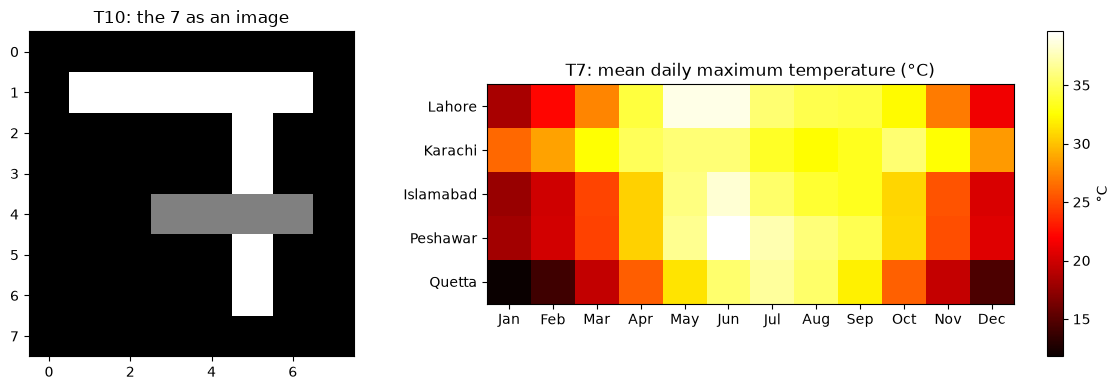

In [15]:
# B3: the "7" and the climate table as images
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})

ax1.imshow(img, cmap="gray")                     # the 8 x 8 "7" from Task 10
ax1.set_title("T10: the 7 as an image")

im = ax2.imshow(tmax, cmap="hot")                # 5 x 12 climate table
ax2.set_xticks(np.arange(12), months)
ax2.set_yticks(np.arange(5), cities)
ax2.set_title("T7: mean daily maximum temperature (°C)")
fig.colorbar(im, ax=ax2, label="°C")

plt.tight_layout()
plt.show()